notebook for exploring how diff models 


In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import HistGradientBoostingClassifier

In [18]:
df = pd.read_parquet("../Data/processed/customers.parquet")

In [19]:
X =df.drop(columns= 'target')
y = df['target']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state =42)

In [24]:
#baseline 

print("models need to be better that baseline: ")

# model always predicting no return
print("Always 0:", accuracy_score(y_test, [0] * len(y_test)))

# simple rule: if customers bought the last 90 days
print("Recency < 90:", accuracy_score(y_test, (X_test["recency"] < 90).astype(int)))

# simple rule: if customers have already come back once
print("frequency > 1: ", accuracy_score(y_test, (X_test["frequency"] >1).astype(int)))

models need to be better that baseline: 
Always 0: 0.5722488038277512
Recency < 90: 0.7043062200956938
frequency > 1:  0.6038277511961723


In [41]:
for depth in [3,4, 5,  7, 8, 9, 12, None]:
    rf = RandomForestClassifier(max_depth=depth, random_state=42)
    scores = cross_validate(rf, X_train, y_train, cv=5, scoring=["accuracy", "roc_auc"])
    print(f"max_depth={depth}:" )
    print(f"roc_auc: {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}")
    print(f"Accuracy: {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}")

max_depth=3:
roc_auc: 0.800 ± 0.010
Accuracy: 0.731 ± 0.013
max_depth=4:
roc_auc: 0.804 ± 0.009
Accuracy: 0.735 ± 0.013
max_depth=5:
roc_auc: 0.805 ± 0.009
Accuracy: 0.736 ± 0.010
max_depth=7:
roc_auc: 0.806 ± 0.007
Accuracy: 0.737 ± 0.009
max_depth=8:
roc_auc: 0.805 ± 0.007
Accuracy: 0.740 ± 0.009
max_depth=9:
roc_auc: 0.803 ± 0.006
Accuracy: 0.734 ± 0.006
max_depth=12:
roc_auc: 0.795 ± 0.005
Accuracy: 0.727 ± 0.008
max_depth=None:
roc_auc: 0.783 ± 0.006
Accuracy: 0.716 ± 0.003


[Text(0.5, 0.8333333333333334, 'orders_per_month <= 0.297\ngini = 0.49\nsamples = 4179\nvalue = [2390, 1789]'),
 Text(0.25, 0.5, 'orders_per_month <= 0.165\ngini = 0.386\nsamples = 2573\nvalue = [1901, 672]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.292\nsamples = 1589\nvalue = [1307, 282]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.479\nsamples = 984\nvalue = [594, 390]'),
 Text(0.75, 0.5, 'monetary <= 2366.365\ngini = 0.424\nsamples = 1606\nvalue = [489, 1117]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.49\nsamples = 804\nvalue = [346, 458]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.293\nsamples = 802\nvalue = [143, 659]')]

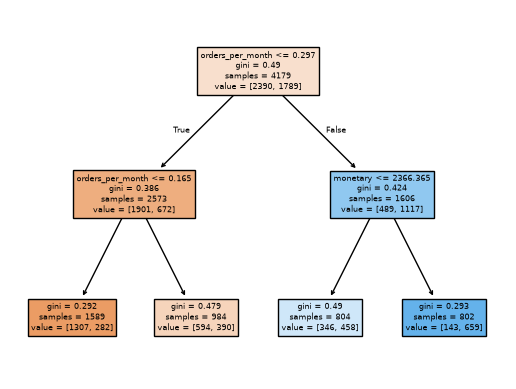

In [45]:


tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X_train, y_train)
plot_tree(tree, feature_names=X.columns, filled=True)

In [36]:
hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

In [37]:
scores = cross_validate(rf, X_train, y_train, cv=5, scoring=["accuracy", "roc_auc"])

print(f"roc_auc: {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}")
print(f"Accuracy: {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}")

roc_auc: 0.783 ± 0.006
Accuracy: 0.716 ± 0.003
